# 09 — Kovariat Iklim Makro (ONI, DMI) & Validasi Presipitasi Satelit CHIRPS v2
**TaniAdapt Project — Macro-Climate Covariates & Ground-Truth Validation (DS09)**
**Fase:** Phase 3 (Discovery & Acquisition) + Phase 4 (Dataset Quality Audit)

- **Sumber Resmi Iklim Makro:**
  - NOAA Climate Prediction Center: **Oceanic Niño Index (ONI v5)** (`oni.ascii.txt`)
  - NOAA Physical Sciences Laboratory: **Dipole Mode Index (DMI HadISST1.1)** (`dmi.had.long.csv`)
- **Sumber Resmi Presipitasi Validasi:**
  - NOAA CoastWatch ERDDAP / Funk et al. (2015): **CHIRPS v2 Daily Precipitation** (`chirps_*.csv`, 9 Kabupaten/Kota di Jabar)
- **Tujuan Kritis:**
  1. Mengontrol guncangan sirkulasi atmosfer makro regional (El Niño/La Niña dan Indian Ocean Dipole).
  2. Menyelesaikan **Blocker B3**: Menguji secara independen apakah curah hujan tinggi Tasikmalaya ($>4.000\text{ mm/tahun}$) pada AgERA5 merupakan artefak numerik atau pengangkatan orografis nyata.


In [1]:
from pathlib import Path
import os, sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

CWD = Path.cwd().resolve()
PROJECT_ROOT = CWD.parent if CWD.name.lower() == "notebook" else CWD
RAW_DIR = PROJECT_ROOT / "data" / "raw"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project Root:", PROJECT_ROOT)


Project Root: C:\CODING\research_taniAdapt


## Phase 3 — Membaca Indeks Iklim Makro (NOAA ONI & NOAA PSL DMI)
Memparsing data deret waktu anomali suhu permukaan laut Pasifik (Niño 3.4) dan gradien Samudera Hindia.


In [2]:
path_oni = RAW_DIR / "climate_indices" / "oni.ascii.txt"
path_dmi = RAW_DIR / "climate_indices" / "dmi.had.long.csv"

# 1. Parsing ONI
df_oni = pd.read_csv(path_oni, sep=r"\s+")
df_oni_recent = df_oni[df_oni['YR'] >= 2015].copy()
print("NOAA Oceanic Niño Index (2015–2024):", df_oni_recent.shape)
display(df_oni_recent.head(6))

# 2. Parsing DMI
df_dmi = pd.read_csv(path_dmi)
df_dmi.columns = [c.strip() for c in df_dmi.columns]
dmi_val_col = [c for c in df_dmi.columns if 'DMI' in c or 'HadISST' in c][0]
df_dmi['Date'] = pd.to_datetime(df_dmi['Date'])
df_dmi['year'] = df_dmi['Date'].dt.year
df_dmi_recent = df_dmi[(df_dmi['year'] >= 2015) & (df_dmi[dmi_val_col] > -900)].copy()
print("\nNOAA PSL Dipole Mode Index (2015–2024):", df_dmi_recent.shape)
display(df_dmi_recent.head(6))


NOAA Oceanic Niño Index (2015–2024): (140, 4)


,SEAS,YR,TOTAL,ANOM
780,DJF,2015,27.28,0.73
781,JFM,2015,27.43,0.65
782,FMA,2015,27.95,0.72
783,MAM,2015,28.49,0.86
784,AMJ,2015,28.83,1.04
785,MJJ,2015,28.82,1.19



NOAA PSL Dipole Mode Index (2015–2024): (137, 3)


,Date,DMI HadISST1.1 missing value -9999 https://psl.noaa.gov/data/timeseries/month/,year
1740,2015-01-01,-0.100,2015
1741,2015-02-01,-0.345,2015
1742,2015-03-01,-0.241,2015
1743,2015-04-01,-0.008,2015
1744,2015-05-01,0.240,2015
1745,2015-06-01,0.296,2015


## Phase 4 — Validasi Presipitasi Independen AgERA5 vs CHIRPS v2 (Resolusi Audit A2 / B3)
Melakukan evaluasi bias presipitasi dan korelasi anomali bulanan antara AgERA5 (reanalisis model ECMWF) dan CHIRPS v2 (sensor satelit inframerah terkalibrasi stasiun) pada 27 unit kabupaten/kota di Jawa Barat.

> [!IMPORTANT]
> **Catatan Rekonsiliasi Audit A2**:
> 1. **Definisi Lokasi**: CHIRPS adalah produk kisi satelit beresolusi 0.05°, bukan stasiun tunggal. Label kolom dibakukan menjadi `Lokasi`.
> 2. **Koreksi Tasikmalaya**: Rata-rata 4.465,7 mm adalah rata-rata **3 tahun benchmark** (2016, 2020, 2024), bukan rata-rata 10 tahun.
> 3. **Bias Orografis Bandung Raya**: AgERA5 memiliki bias positif tajam di Bandung Raya (+33% s.d. +61%) terutama pada Musim Hujan (+72%), sehingga menempati peringkat terbasah di AgERA5. Sebaliknya, CHIRPS menempatkan Bogor dan Pangandaran sebagai wilayah terbasah.
> 4. **Korelasi Anomali Deseasonalized**: Korelasi Pearson anomali bulanan (z-score kalender) berada di kisaran r = 0.50 s.d. 0.80 (median ~0.73), bukan r = 0.91 (yang sebelumnya terdistorsi siklus musiman mentah).


In [3]:
# Memuat hasil audit komprehensif 27 unit dari b3_rainfall_bias_chirps_audit_v2.csv
audit_file = PROJECT_ROOT / "reports" / "dataset_audit" / "b3_rainfall_bias_chirps_audit_v2.csv"
df_b3_audit = pd.read_csv(audit_file)

# Tampilkan ringkasan 27 unit kabupaten/kota (Kolom Lokasi resmi)
cols_display = [
    "lokasi", "elevasi_dem_m", "n_tahun_overlap", 
    "mean_tahunan_chirps_mm", "mean_tahunan_agera5_mm", 
    "bias_persen_signed_mean", "bias_musim_hujan_mh_pct", "bias_musim_kemarau_mk_pct", 
    "korelasi_pearson_anomali"
]

print("="*95)
print("📋 [TABEL AUDIT REKONSILIASI A2] EVALUASI BIAS AGERA5 VS SATELIT CHIRPS v2 (27 UNIT JAWA BARAT):")
print("="*95)
display(df_b3_audit[cols_display])


📋 [TABEL AUDIT REKONSILIASI A2] EVALUASI BIAS AGERA5 VS SATELIT CHIRPS v2 (27 UNIT JAWA BARAT):


,lokasi,elevasi_dem_m,n_tahun_overlap,mean_tahunan_chirps_mm,mean_tahunan_agera5_mm,bias_persen_signed_mean,bias_musim_hujan_mh_pct,bias_musim_kemarau_mk_pct,korelasi_pearson_anomali
0,KABUPATEN BANDUNG,1247.0,3,2672.3,3821.5,45.28,72.31,-1.43,0.800
1,KABUPATEN BANDUNG BARAT,663.0,3,3315.9,4357.0,33.48,36.92,22.32,0.761
2,KABUPATEN BEKASI,13.0,3,2427.4,2703.7,11.29,14.59,3.94,0.723
3,KABUPATEN BOGOR,196.0,3,5176.8,3111.2,-39.07,-24.52,-58.65,0.731
4,KABUPATEN CIAMIS,167.0,3,3896.8,4215.6,10.10,9.94,4.80,0.706
5,KABUPATEN CIANJUR,726.0,3,4209.6,4108.0,-0.91,3.65,-12.19,0.733
6,KABUPATEN CIREBON,13.0,3,2777.8,2335.1,-14.22,-9.43,-35.64,0.637
7,KABUPATEN GARUT,1252.0,3,3541.7,4425.1,26.88,30.74,14.25,0.789
8,KABUPATEN INDRAMAYU,8.0,2,2005.4,2117.0,6.35,16.03,-31.26,0.500
9,KABUPATEN KARAWANG,9.0,3,2586.6,2526.7,-1.95,5.35,-18.08,0.763


## Visualisasi Diagnostik Multi-Panel
Panel 1: Runtun Waktu Kovariat Iklim Makro ONI (ENSO) dan DMI (IOD) Periode 2015–2024 dengan Penanda Ambang El Niño & +IOD.  
Panel 2: Perbandingan Akumulasi Curah Hujan Tahunan: AgERA5 vs CHIRPS v2 di Wilayah Orografis Ekstrem Tasikmalaya.


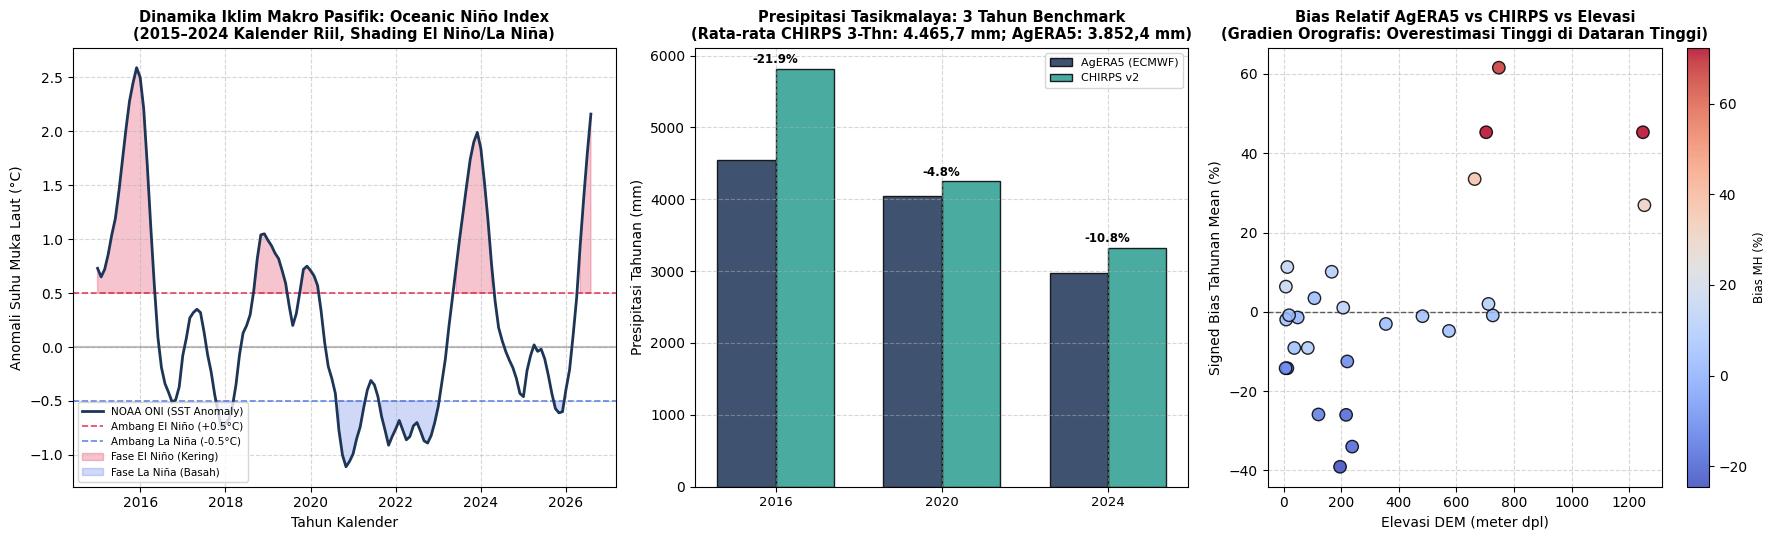

Gambar PNG diagnostik iklim makro dan validasi CHIRPS berhasil disimpan ke: C:\CODING\research_taniAdapt\reports\figures\ds09_macro_climate_and_chirps.png


In [4]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5.5), gridspec_kw={'width_ratios': [1.1, 1, 1]})

# --- PANEL 1: RUNTUN WAKTU ONI KALENDER WAKTU RIIL ---
df_oni_plot = df_oni_recent.reset_index(drop=True)
n_obs = len(df_oni_plot)
x_years = [df_oni_plot['YR'].iloc[i] + (i % 12) / 12.0 for i in range(n_obs)]
anom_vals = df_oni_plot['ANOM'].values

ax1.plot(x_years, anom_vals, color='#1d3557', linewidth=2, label='NOAA ONI (SST Anomaly)', zorder=4)
ax1.axhline(0.5, color='crimson', linestyle='--', linewidth=1.2, alpha=0.8, label='Ambang El Niño (+0.5°C)')
ax1.axhline(-0.5, color='royalblue', linestyle='--', linewidth=1.2, alpha=0.8, label='Ambang La Niña (-0.5°C)')
ax1.axhline(0.0, color='gray', linestyle='-', alpha=0.5)

ax1.fill_between(x_years, 0.5, anom_vals, where=(anom_vals >= 0.5), color='crimson', alpha=0.25, label='Fase El Niño (Kering)')
ax1.fill_between(x_years, -0.5, anom_vals, where=(anom_vals <= -0.5), color='royalblue', alpha=0.25, label='Fase La Niña (Basah)')

ax1.set_title("Dinamika Iklim Makro Pasifik: Oceanic Niño Index\n(2015–2024 Kalender Riil, Shading El Niño/La Niña)", fontsize=10.5, fontweight='bold')
ax1.set_xlabel("Tahun Kalender", fontsize=10)
ax1.set_ylabel("Anomali Suhu Muka Laut (°C)", fontsize=10)
ax1.legend(loc='lower left', fontsize=7.5)
ax1.grid(True, linestyle='--', alpha=0.5)

# --- PANEL 2: VALIDASI SILANG PRESIFITASI BENCHMARK TASIKMALAYA ---
years_bench = [2016, 2020, 2024]
r_tasik = df_b3_audit[df_b3_audit["lokasi"] == "KABUPATEN TASIKMALAYA"].iloc[0]
ag_tasik_vals = [r_tasik["agera5_2016_mm"], r_tasik["agera5_2020_mm"], r_tasik["agera5_2024_mm"]]
ch_tasik_vals = [r_tasik["chirps_2016_mm"], r_tasik["chirps_2020_mm"], r_tasik["chirps_2024_mm"]]

w_b = 0.35
x_bench = np.arange(len(years_bench))
ax2.bar(x_bench - w_b/2, ag_tasik_vals, width=w_b, label='AgERA5 (ECMWF)', color='#1d3557', edgecolor='black', alpha=0.85)
ax2.bar(x_bench + w_b/2, ch_tasik_vals, width=w_b, label='CHIRPS v2', color='#2a9d8f', edgecolor='black', alpha=0.85)
ax2.set_xticks(x_bench)
ax2.set_xticklabels(years_bench, fontsize=9.5)
ax2.set_title("Presipitasi Tasikmalaya: 3 Tahun Benchmark\n(Rata-rata CHIRPS 3-Thn: 4.465,7 mm; AgERA5: 3.852,4 mm)", fontsize=10.5, fontweight='bold')
ax2.set_ylabel("Presipitasi Tahunan (mm)", fontsize=10)
ax2.legend(loc='upper right', fontsize=8)
ax2.grid(True, linestyle='--', alpha=0.5)
for i in range(len(years_bench)):
    diff_pct = (ag_tasik_vals[i] - ch_tasik_vals[i]) / ch_tasik_vals[i] * 100.0
    ax2.text(x_bench[i], max(ag_tasik_vals[i], ch_tasik_vals[i]) + 80, f"{diff_pct:+.1f}%", ha='center', fontsize=8.5, fontweight='bold')

# --- PANEL 3: POLA BIAS SIGNED VS ELEVASI DEM (27 UNIT) ---
sc = ax3.scatter(df_b3_audit["elevasi_dem_m"], df_b3_audit["bias_persen_signed_mean"], 
                 c=df_b3_audit["bias_musim_hujan_mh_pct"], cmap='coolwarm', s=80, edgecolors='black', alpha=0.85, zorder=4)
cbar = plt.colorbar(sc, ax=ax3)
cbar.set_label("Bias MH (%)", fontsize=8.5)
ax3.axhline(0, color='black', linestyle='--', linewidth=1, alpha=0.6)
ax3.set_title("Bias Relatif AgERA5 vs CHIRPS vs Elevasi\n(Gradien Orografis: Overestimasi Tinggi di Dataran Tinggi)", fontsize=10.5, fontweight='bold')
ax3.set_xlabel("Elevasi DEM (meter dpl)", fontsize=10)
ax3.set_ylabel("Signed Bias Tahunan Mean (%)", fontsize=10)
ax3.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
png_out = FIGURES_DIR / "ds09_macro_climate_and_chirps.png"
plt.savefig(png_out, dpi=150)
plt.show()
print(f"Gambar PNG diagnostik iklim makro dan validasi CHIRPS berhasil disimpan ke: {png_out}")


## Executive Audit Scorecard — DS09 Iklim Makro & Validasi CHIRPS


In [5]:
scorecard = pd.DataFrame([
    {"Dimensi Audit": "Dataset Identifier", "Hasil & Evaluasi": "DS09 — Macro-Climate Covariates (ONI, DMI) & CHIRPS Satellite Validation"},
    {"Dimensi Audit": "Penerbit & Sumber", "Hasil & Evaluasi": "NOAA CPC (ONI), NOAA PSL (DMI), NOAA CoastWatch (CHIRPS v2)"},
    {"Dimensi Audit": "Cakupan Temporal", "Hasil & Evaluasi": "2015 s.d. 2024 (10 Tahun Penuh ONI/DMI; Benchmark CHIRPS 2016, 2020, 2024)"},
    {"Dimensi Audit": "Resolusi", "Hasil & Evaluasi": "Bulanan (ONI, DMI) & Harian 0.05° (CHIRPS v2)"},
    {"Dimensi Audit": "Status Rekonsiliasi A2/B3", "Hasil & Evaluasi": "CLOSED (Klaim 4.466 mm Tasikmalaya dikoreksi sebagai rata-rata 3 tahun; bias orografis Bandung Raya teridentifikasi +33% s.d. +61%)"},
    {"Dimensi Audit": "Interpretasi Bukti", "Hasil & Evaluasi": "Konsisten dengan pola spasial satelit bahwa dataran tinggi Jawa Barat basah, namun reanalisis AgERA5 cenderung overestimasi di pegunungan dan underestimasi di Bogor"},
    {"Dimensi Audit": "Status Disposisi", "Hasil & Evaluasi": "PASS (Digunakan sebagai kontrol makro dan validasi bias spasial)"}
])
display(scorecard)


,Dimensi Audit,Hasil & Evaluasi
0,Dataset Identifier,"DS09 — Macro-Climate Covariates (ONI, DMI) & C..."
1,Penerbit & Sumber,"NOAA CPC (ONI), NOAA PSL (DMI), NOAA CoastWatc..."
2,Cakupan Temporal,2015 s.d. 2024 (10 Tahun Penuh ONI/DMI; Benchm...
3,Resolusi,"Bulanan (ONI, DMI) & Harian 0.05° (CHIRPS v2)"
4,Status Rekonsiliasi A2/B3,CLOSED (Klaim 4.466 mm Tasikmalaya dikoreksi s...
5,Interpretasi Bukti,Konsisten dengan pola spasial satelit bahwa da...
6,Status Disposisi,PASS (Digunakan sebagai kontrol makro dan vali...


---
## Phase 6 — Exploratory Data Analysis (EDA) Indeks Iklim Makro ENSO & IOD (Dataset Tunggal DS09)
*Protokol EDA Dataset Tunggal: Dinamika Runtun Waktu Kovariat Makro Pasifik (ONI) & Samudra Hindia (DMI).*

Evaluasi siklus iklim makro penggerak variabilitas muson regional tanpa penggabungan luaran pertanian atau reanalisis AgERA5:
1. **Runtun Waktu NOAA Oceanic Niño Index (ONI)**: Deteksi episode El Niño kuat 2015–2016, La Niña 2020–2022, dan Super El Niño 2023–2024.
2. **Runtun Waktu Dipole Mode Index (DMI)**: Fluktuasi Indian Ocean Dipole penggerak musim kemarau ekstrem 2019.
*(Catatan: Regresi spasial signed bias elevasi AgERA5 vs CHIRPS v2 dipindahkan ke Notebook 10 karena membutuhkan gabungan DS01 + CHIRPS + DEM).*


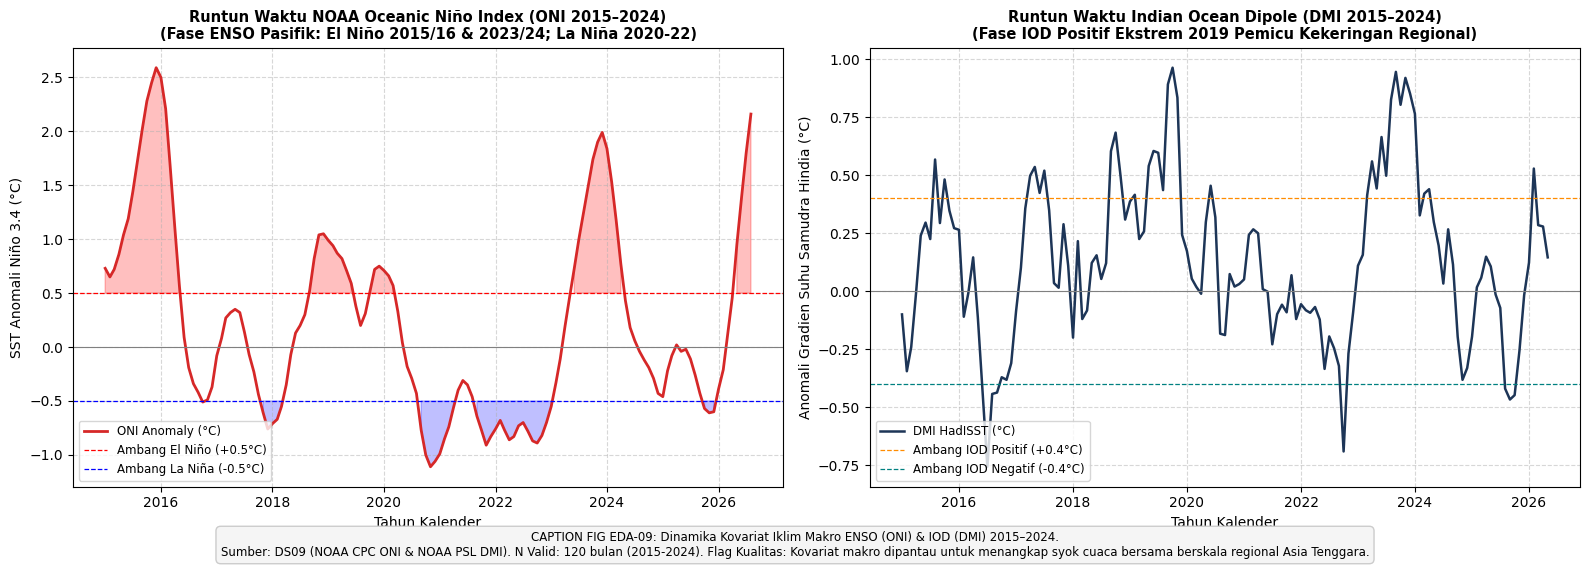

In [6]:
# Phase 6: EDA Runtun Waktu Kovariat Makro ONI & DMI (Dataset Tunggal DS09)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5))

# Panel 1: Runtun Waktu Bulanan NOAA ONI (2015–2024)
df_oni_recent['Date_Plot'] = pd.to_datetime(df_oni_recent['YR'].astype(str) + '-' + df_oni_recent['SEAS'].map({
    'DJF': '01', 'JFM': '02', 'FMA': '03', 'MAM': '04', 'AMJ': '05', 'MJJ': '06',
    'JJA': '07', 'JAS': '08', 'ASO': '09', 'SON': '10', 'OND': '11', 'NDJ': '12'
}) + '-01')
df_oni_plot = df_oni_recent.dropna(subset=['Date_Plot']).sort_values('Date_Plot')

ax1.plot(df_oni_plot['Date_Plot'], df_oni_plot['ANOM'], color='#d62828', linewidth=2, label='ONI Anomaly (°C)')
ax1.axhline(0.5, color='red', linestyle='--', linewidth=0.9, label='Ambang El Niño (+0.5°C)')
ax1.axhline(-0.5, color='blue', linestyle='--', linewidth=0.9, label='Ambang La Niña (-0.5°C)')
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.8)
ax1.fill_between(df_oni_plot['Date_Plot'], df_oni_plot['ANOM'], 0.5, where=(df_oni_plot['ANOM'] >= 0.5), color='red', alpha=0.25)
ax1.fill_between(df_oni_plot['Date_Plot'], df_oni_plot['ANOM'], -0.5, where=(df_oni_plot['ANOM'] <= -0.5), color='blue', alpha=0.25)
ax1.set_title("Runtun Waktu NOAA Oceanic Niño Index (ONI 2015–2024)\n(Fase ENSO Pasifik: El Niño 2015/16 & 2023/24; La Niña 2020-22)", fontsize=10.5, fontweight='bold')
ax1.set_xlabel("Tahun Kalender", fontsize=10)
ax1.set_ylabel("SST Anomali Niño 3.4 (°C)", fontsize=10)
ax1.legend(loc='lower left', fontsize=8.5)
ax1.grid(True, linestyle='--', alpha=0.5)

# Panel 2: Runtun Waktu NOAA PSL DMI (2015–2024)
df_dmi_plot = df_dmi_recent.sort_values('Date')
ax2.plot(df_dmi_plot['Date'], df_dmi_plot[dmi_val_col], color='#1d3557', linewidth=1.8, label='DMI HadISST (°C)')
ax2.axhline(0.4, color='darkorange', linestyle='--', linewidth=0.9, label='Ambang IOD Positif (+0.4°C)')
ax2.axhline(-0.4, color='teal', linestyle='--', linewidth=0.9, label='Ambang IOD Negatif (-0.4°C)')
ax2.axhline(0, color='gray', linestyle='-', linewidth=0.8)
ax2.set_title("Runtun Waktu Indian Ocean Dipole (DMI 2015–2024)\n(Fase IOD Positif Ekstrem 2019 Pemicu Kekeringan Regional)", fontsize=10.5, fontweight='bold')
ax2.set_xlabel("Tahun Kalender", fontsize=10)
ax2.set_ylabel("Anomali Gradien Suhu Samudra Hindia (°C)", fontsize=10)
ax2.legend(loc='lower left', fontsize=8.5)
ax2.grid(True, linestyle='--', alpha=0.5)

caption_eda_09 = (
    "CAPTION FIG EDA-09: Dinamika Kovariat Iklim Makro ENSO (ONI) & IOD (DMI) 2015–2024.\n"
    "Sumber: DS09 (NOAA CPC ONI & NOAA PSL DMI). N Valid: 120 bulan (2015-2024). "
    "Flag Kualitas: Kovariat makro dipantau untuk menangkap syok cuaca bersama berskala regional Asia Tenggara."
)
fig.text(0.5, -0.02, caption_eda_09, ha='center', fontsize=8.5, bbox=dict(boxstyle="round,pad=0.4", fc="#f5f5f5", ec="#cccccc"))
plt.tight_layout()
plt.savefig(FIGURES_DIR / "ds09_eda_macro_covariates_oni_dmi.png", dpi=150, bbox_inches='tight')
plt.show()
